In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from scipy import stats

# Set visual style
plt.style.use('default')
sns.set_theme(style='whitegrid', palette='husl')
np.random.seed(42)

In [26]:
baseline_latency_ms = np.array([45, 52, 48, 50, 47, 53, 49, 51, 46, 54, 48, 52])
mean_latency = np.mean(baseline_latency_ms)
median_latency = np.median(baseline_latency_ms)

latency_with_timeout = np.append(baseline_latency_ms,[1200])
mean_latency_with_timeout = np.mean(latency_with_timeout)
median_latency_with_timeout = np.median(latency_with_timeout)

percent_change_mean = (mean_latency-mean_latency_with_timeout)/mean_latency
percent_change_median = (median_latency-median_latency_with_timeout)/median_latency

print(f"Baseline mean: {mean_latency:.1f} vs contaminated mean: {mean_latency_with_timeout:.1f}")
print(f"Baseline median: {median_latency:.1f} vs contaminated median: {median_latency_with_timeout:.1f}")

Baseline mean: 49.6 vs contaminated mean: 138.1
Baseline median: 49.5 vs contaminated median: 50.0


In [25]:
np.random.seed(42)
# Generates positive, right-skewed salary values
salaries = np.random.lognormal(mean=4.5, sigma=0.6, size=1000)

mean_salary = np.mean(salaries)
median_salary = np.median(salaries)
mode_salary = Counter(np.round(salaries)).most_common(1)[0][0]


if mode_salary < median_salary and median_salary < mean_salary:
    print("data is right skewed")
elif mode_salary > median_salary and median_salary > mean_salary:
    print("data is left skewed")
else:
    print("data is symmetric")

data is right skewed


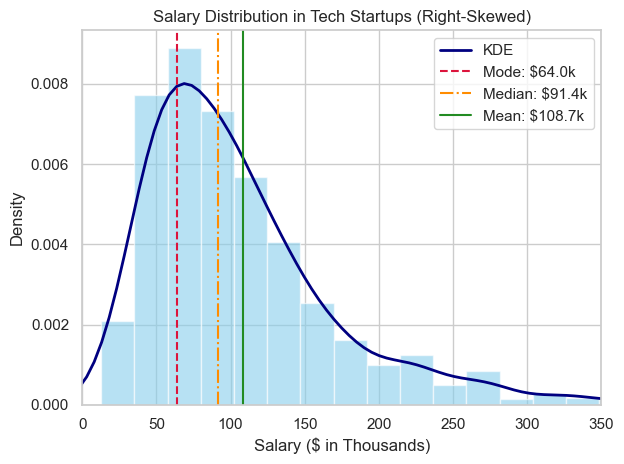

In [24]:
fig, ax = plt.subplots()
ax.hist(salaries, bins=40, density=True, alpha=0.6, color="skyblue", edgecolor="white")
sns.kdeplot(salaries, color='navy', linewidth=2, label='KDE')
ax.axvline(mode_salary, linestyle='--', color='crimson', label=f'Mode: ${mode_salary:.1f}k')
ax.axvline(float(median_salary), linestyle='-.', color='darkorange', label=f'Median: ${median_salary:.1f}k')
ax.axvline(float(mean_salary), linestyle='-', color='forestgreen', label=f'Mean: ${mean_salary:.1f}k')

ax.set_title("Salary Distribution in Tech Startups (Right-Skewed)")
ax.set_xlabel("Salary ($ in Thousands)")
ax.set_xlim(0,350)
ax.legend()
plt.tight_layout()